# Noisy Pasqal QRC

Quantum reservoir computing (QRC) with neutral atoms. For each time step t we take a window of the input signal x. Each value in the window sets the *detuning* of one laser pulse. After the pulses we measure the atoms and use the excitation statistics as features to estimate y[t]. The quantum system is fixed; only the linear readout is trained.

**Pipeline**

1. Load the data, split it chronologically into train/test, scale the input and build sliding windows.
2. Define the hardware noise model.
3. Place the atoms (the register).
4. Build a parametrised pulse sequence: one pulse per value in the window.
5. Configure the simulator.
6. Define how measured bitstrings become features.
7. Run the reservoir on every window.
8. Train a ridge regression on the features.
9. Evaluate on the test period and compare with a classical baseline.

**To start**, select the `qml` environment and run all cells in order. The demo uses 48 synthetic data points and runs locally with Pulser and QuTiP. To use your own data, edit the cell in section 1.

## 0. Setup

In [1]:
# Optional: install the dependencies if your environment does not have them yet.
# %pip install pulser-core==1.10.0 pulser-simulation==1.10.0 numpy matplotlib pandas

import matplotlib.pyplot as plt  # plotting
import numpy as np               # arrays and linear algebra

# Pulser describes the hardware, the atom positions and the laser pulses
from pulser import NoiseModel, Pulse, Register, Sequence
from pulser.backend import BitStrings    # observable: sample measured bitstrings
from pulser.devices import AnalogDevice  # specs of a realistic Pasqal analog device

# Local emulator that solves the atom dynamics with QuTiP
from pulser_simulation import QutipBackendV2, QutipConfig

SEED = 1  # fixes every random number so the run is reproducible

## 1. Data

Use one scalar input `x_raw[t]` and one scalar target `y_raw[t]` per row, in chronological order. Set the CSV path and column names, or assign your two NumPy arrays directly on the indicated line. Values can be in their original units.

The estimate of y[t] uses the inputs up to and including x[t]. To forecast one step ahead, align the future value as the target, e.g. `x_raw, y_raw = series[:-1], series[1:]`.

The demo is a one-step memory task: the inputs are random numbers and the target y[t] is the previous input x[t−1].

In [2]:
CSV_PATH = None                # e.g. "my_data.csv"; None uses the synthetic demo
X_COLUMN, Y_COLUMN = "x", "y"  # column names for the input and the target

if CSV_PATH is None:
    # Synthetic one-step memory task: random inputs, target = previous input
    rng = np.random.default_rng(SEED)
    x_raw = rng.uniform(0, 1, size=48)           # 48 random inputs in [0, 1]
    y_raw = np.concatenate(([0.0], x_raw[:-1]))  # y[t] = x[t-1]; y[0] is a placeholder that gets dropped
    # To use your own arrays instead, uncomment and edit:
    # x_raw, y_raw = my_input, my_target
else:
    import pandas as pd
    data = pd.read_csv(CSV_PATH)
    x_raw = data[X_COLUMN].to_numpy(float)  # input signal
    y_raw = data[Y_COLUMN].to_numpy(float)  # target signal

print(f"{len(x_raw)} rows loaded")

48 rows loaded


### 1.1 Window size and train/test split

`WINDOW` is how many consecutive inputs the reservoir sees per prediction; each one becomes a pulse. The split is chronological (no shuffling): the first 70 % of the rows fit the readout and the last 30 % measure the error.

In [3]:
WINDOW = 2  # inputs per window = pulses per sequence; 2 is the minimum that contains x[t-1]

split = int(0.70 * len(x_raw))  # index of the first test row in x_raw

# Window j covers rows j ... j+WINDOW-1, so windows start WINDOW-1 rows later than the data.
# The last training window must end at row split-1, hence:
n_train = split - (WINDOW - 1)

### 1.2 Scale the input to [0, 1]

The scaled value is mapped to a detuning later, so it must lie in [0, 1]. The minimum and maximum come from the training rows only, so no information leaks from the test period. The target keeps its original units.

In [4]:
x_min, x_max = x_raw[:split].min(), x_raw[:split].max()  # training range only
x = (x_raw - x_min) / (x_max - x_min)                     # min-max scaling

# Test values outside the training range are clipped, so every detuning stays
# inside the physical range defined in the pulse sequence.
x = np.clip(x, 0, 1)

### 1.3 Sliding windows

Each row of `windows` holds `WINDOW` consecutive inputs, (x[t−1], x[t]) for `WINDOW = 2`, and is paired with the target y[t] of its last step. The first `WINDOW − 1` rows have no complete history and are dropped.

In [5]:
windows = np.lib.stride_tricks.sliding_window_view(x, WINDOW)  # shape: (len(x) - WINDOW + 1, WINDOW)
y = y_raw[WINDOW - 1:]  # target aligned with the last step of each window

print(f"windows shape: {windows.shape}")
print(f"{n_train} training windows and {len(y) - n_train} test windows")
print(f"first window: {windows[0]} -> target {y[0]:.4f}")

windows shape: (47, 2)
32 training windows and 15 test windows
first window: [0.5080504 0.9682394] -> target 0.5118


## 2. Noise model (FC1)

The model uses the FC1 values for preparation and readout errors, laser fluctuations between runs, the beam's spatial profile, thermal motion and the two effective decoherence channels. The demo leaves out the high-frequency phase-noise spectrum and systematic calibration offsets. [Table II of Dalyac et al.](https://arxiv.org/pdf/2607.28364#page=14)

In equation (7) of the paper, γ₂ = 0.05 µs⁻¹ multiplies the dissipator of the Rydberg projector. Pulser uses twice its `dephasing_rate` parameter as the coefficient of that dissipator, so we pass γ₂/2. [Pulser 1.10.0 implementation](https://github.com/pasqal-io/Pulser/blob/v1.10.0/pulser-core/pulser/_hamiltonian_data/hamiltonian_data.py#L685-L700)

In [6]:
GAMMA_2 = 0.05  # µs⁻¹, coefficient of the Rydberg-projector dissipator in the paper

noise_model = NoiseModel(
    # SPAM: state preparation and measurement errors
    state_prep_error=0.018,            # probability that an atom is not prepared in |g⟩
    p_false_pos=0.01,                  # probability of reading 1 when the atom is in |g⟩
    p_false_neg=0.07,                  # probability of reading 0 when the atom is in |r⟩
    # Laser fluctuations, redrawn for every trajectory
    amp_sigma=0.003,                   # relative std of the Rabi frequency, σΩ/Ω
    detuning_sigma=2 * np.pi * 0.008,  # std of the detuning: 8 kHz, in rad/µs
    laser_waist=141.0,                 # µm; Gaussian beam, atoms off-centre see a smaller Ω
    # Thermal motion of the atoms in their optical tweezers
    temperature=20.0,                  # µK; causes Doppler shifts
    trap_waist=0.84,                   # µm; tweezer size
    trap_depth=70.0,                   # µK; with the temperature, sets the position jitter
    # Decoherence channels, solved inside the master equation
    relaxation_rate=0.01,              # µs⁻¹; decay from |r⟩ to |g⟩
    dephasing_rate=GAMMA_2 / 2,        # µs⁻¹; Pulser doubles it, see the note above
)
print("Active noise:", ", ".join(noise_model.noise_types))

Active noise: SPAM, amplitude, dephasing, detuning, doppler, register, relaxation


## 3. Atom register

The geometry sets how strongly the atoms interact (the interaction falls as 1/r⁶). At Ω = 2π rad/µs the blockade radius of `AnalogDevice` is about 7.2 µm, so with a 7 µm spacing neighbouring atoms interact about as strongly as the laser drives them.

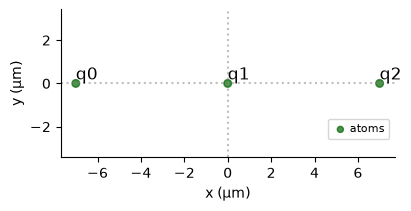

In [7]:
# Three atoms on a line, 7 µm apart; qubit IDs are "q0", "q1", "q2"
register = Register.rectangle(1, 3, spacing=7.0, prefix="q")

# AnalogDevice requires a trap layout; this builds one that fits the register
register = register.with_automatic_layout(AnalogDevice)

register.draw()  # plot the atom positions

## 4. Pulse sequence

Each window starts from freshly prepared atoms. Within the window the state evolves from one pulse to the next without a reset, so the final measurement depends on the whole window. The demo uses two pulses of 500 ns and a detuning range from −0.5 to +1.5 MHz (before multiplying by 2π).

In [8]:
# A sequence = a register + a device + the pulses applied on its channels
sequence = Sequence(register, AnalogDevice)

# One global laser that couples |g⟩ and |r⟩ on all atoms at once
sequence.declare_channel("ryd", "rydberg_global")

# Pulse parameters (Pulser units: durations in ns, Ω and δ in rad/µs)
TAU_NS = 500                  # duration of each pulse
OMEGA = 2 * np.pi             # Rabi frequency: 1 MHz
DELTA_MIN = -2 * np.pi * 0.5  # detuning for an input of 0: -0.5 MHz
DELTA_MAX = 2 * np.pi * 1.5   # detuning for an input of 1: +1.5 MHz

# "x" is a placeholder for the WINDOW values of one window; it is filled in at build time
x_var = sequence.declare_variable("x", size=WINDOW)

# One constant pulse per input value, applied back to back
for value in x_var:
    detuning = DELTA_MIN + (DELTA_MAX - DELTA_MIN) * value  # linear map [0, 1] -> [δmin, δmax]
    sequence.add(Pulse.ConstantPulse(TAU_NS, OMEGA, detuning, 0.0), "ryd")  # last argument: phase

# Measure every atom in the ground/Rydberg basis: 0 = ground, 1 = Rydberg
sequence.measure("ground-rydberg")

## 5. Simulator configuration

Each trajectory draws one realisation of the preparation, laser and position noise. QuTiP solves the master equation, with relaxation and dephasing, for that realisation. Bitstrings are then sampled with readout errors. 12 trajectories × 40 shots give 480 bitstrings per window; the shots of one trajectory share the same physical noise realisation. This budget is sized for the demo.

In [9]:
N_TRAJECTORIES = 12        # noise realisations per window
SHOTS_PER_TRAJECTORY = 40  # bitstrings sampled from each realisation -> 480 per window

config = QutipConfig(
    noise_model=noise_model,
    n_trajectories=N_TRAJECTORIES,
    # Sample bitstrings at the end of the sequence (1.0 = 100 % of its duration)
    observables=[BitStrings(evaluation_times=[1.0], num_shots=SHOTS_PER_TRAJECTORY)],
    solver="MasterEquation",  # evolve the density matrix (includes relaxation and dephasing)
    with_modulation=True,     # smooth the pulse edges as the real laser modulator does
)

## 6. From bitstrings to features

For example, the bitstring `101` counts as an excitation of atoms 0 and 2, and as a joint excitation of the pair (0, 2). Averaging these indicators over all shots gives six features per window: three occupations ⟨nᵢ⟩ and three pair correlations ⟨nᵢnⱼ⟩.

In [10]:
# All pairs (i, j) with i < j; for 3 atoms: (0, 1), (0, 2), (1, 2)
pairs = np.triu_indices(len(register.qubit_ids), k=1)


def features_from_counts(counts):
    """Turn {bitstring: count} into occupations ⟨n_i⟩ and pair correlations ⟨n_i n_j⟩."""
    bits = np.array([list(b) for b in counts], dtype=float)  # one row per bitstring: "101" -> [1, 0, 1]
    p = np.array(list(counts.values()), dtype=float)         # how often each bitstring was seen
    p /= p.sum()                                             # counts -> empirical probabilities
    occupations = p @ bits                # ⟨n_i⟩: probability that atom i is excited
    joint = bits.T @ (p[:, None] * bits)  # ⟨n_i n_j⟩: probability that atoms i and j are both excited
    return np.concatenate([occupations, joint[pairs]])  # 3 occupations + 3 pairs = 6 features

## 7. Run the reservoir on every window

This is the slow step: one noisy simulation per window.

In [11]:
np.random.seed(SEED)  # Pulser draws its noise and shots from NumPy's global generator

features = []
for window in windows:
    built = sequence.build(x=window.tolist())             # fill "x" with this window -> concrete sequence
    result = QutipBackendV2(built, config=config).run()   # simulate with noise and sample bitstrings
    features.append(features_from_counts(result.final_bitstrings))  # compress shots into 6 numbers

features = np.array(features)  # shape: (number of windows, number of features)
print(f"features shape: {features.shape}")

features shape: (47, 6)


## 8. Readout: ridge regression

The only trained part. Inputs and target are centred so the intercept is not penalised, and the weights come from the closed-form ridge solution w = (AᵀA + αI)⁻¹ Aᵀ(y − ȳ).

In [12]:
RIDGE_ALPHA = 1e-3  # regularisation strength: larger values shrink the weights more


def predict_test(inputs):
    """Fit ridge regression on the training windows and predict the test windows."""
    train, test = inputs[:n_train], inputs[n_train:]           # chronological split
    x_mean, y_mean = train.mean(axis=0), y[:n_train].mean()   # training means
    A = train - x_mean                                         # centred training inputs
    w = np.linalg.solve(A.T @ A + RIDGE_ALPHA * np.eye(A.shape[1]), A.T @ (y[:n_train] - y_mean))
    return y_mean + (test - x_mean) @ w                        # predictions for the test windows

## 9. Evaluate and compare

We train one ridge regression on the reservoir features and another directly on the input windows (the classical baseline). The MAE is in the units of y. The NMSE divides the mean squared error by the variance of y in the test period: 0 is perfect, 1 is no better than predicting the mean.

In this demo the baseline has direct access to x[t−1], which is the target, so it should be almost perfect; that checks the alignment of windows and targets. The reservoir result shows how much of that input can be recovered from the noisy measurements.

In [13]:
target = y[n_train:]  # true values in the test period

predictions = {
    "Noisy QRC": predict_test(features),       # readout on the 6 reservoir features
    "Ridge on inputs": predict_test(windows),  # baseline: same readout on the raw window
}

for name, pred in predictions.items():
    mae = np.mean(np.abs(pred - target))                   # mean absolute error, in units of y
    nmse = np.mean((pred - target) ** 2) / np.var(target)  # normalised mean squared error
    print(f"{name} · MAE {mae:.4g} · NMSE {nmse:.3f}")

Noisy QRC · MAE 0.08033 · NMSE 0.197
Ridge on inputs · MAE 7.796e-05 · NMSE 0.000


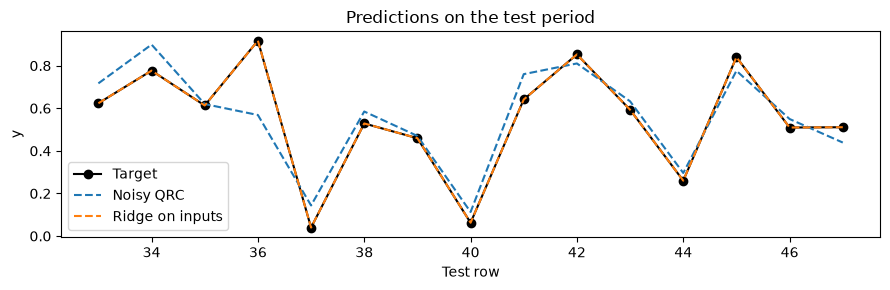

In [14]:
t = np.arange(split, len(y_raw))  # row index in the original data of each test target

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t, target, "o-", color="black", label="Target")
for name, pred in predictions.items():
    ax.plot(t, pred, "--", label=name)
ax.set(xlabel="Test row", ylabel="y", title="Predictions on the test period")
ax.legend()
fig.tight_layout()
plt.show()